# Importing neccessary libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Importing the dataset

In [3]:
price_df = pd.read_excel('/content/Medibuddy Insurance Data Price (1) (2).xlsx')
personal_df = pd.read_excel('/content/Medibuddy insurance data personal details (1) (2).xlsx')

df = pd.merge(price_df, personal_df, on='Policy no.')
df.head()

,Policy no.,age,sex,bmi,charges in INR,children,smoker,region
0,PLC156898,19,female,27.900,16884.92400,0,yes,southwest
1,PLC156907,18,male,33.770,1725.55230,1,no,southeast
2,PLC156916,28,male,33.000,4449.46200,3,no,southeast
3,PLC156925,33,male,22.705,21984.47061,0,no,northwest
4,PLC156934,32,male,28.880,3866.85520,0,no,northwest


In [4]:
df.describe()

,age,bmi,charges in INR,children
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,13270.422265,1.094918
std,14.049960,6.098187,12110.011237,1.205493
min,18.000000,15.960000,1121.873900,0.000000
25%,27.000000,26.296250,4740.287150,0.000000
50%,39.000000,30.400000,9382.033000,1.000000
75%,51.000000,34.693750,16639.912515,2.000000
max,64.000000,53.130000,63770.428010,5.000000


# Questions

1. Does gender matter for extending policies?

In [5]:
gender_claim = df.groupby("sex")["charges in INR"].mean()
gender_claim

,charges in INR
sex,
female,12569.578844
male,13956.751178


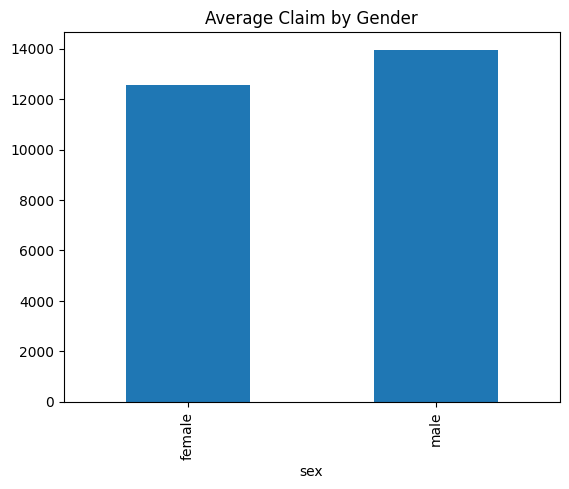

In [6]:
gender_claim.plot(kind="bar", title="Average Claim by Gender")
plt.show()

2. What is the average amount spent per policy?

In [9]:
res = float(df["charges in INR"].mean())
res

13270.422265141257

3. Should policies differ by geographic location?

In [10]:
region_claim = df.groupby("region")["charges in INR"].mean()
region_claim

,charges in INR
region,
northeast,13406.384516
northwest,12417.575374
southeast,14735.411438
southwest,12346.937377


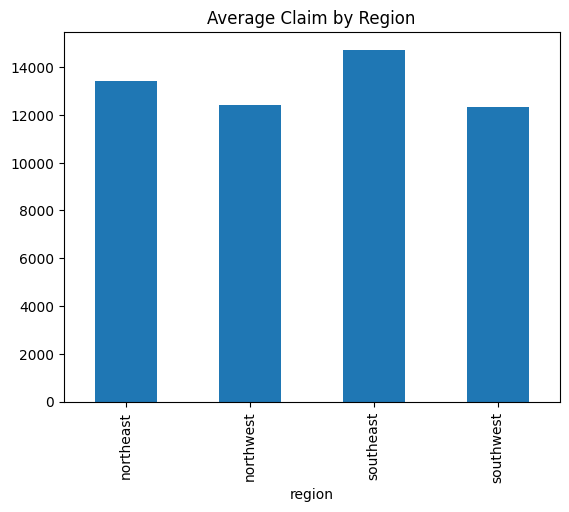

In [11]:
region_claim.plot(kind="bar", title="Average Claim by Region")
plt.show()

4. Does number of dependents affect claim?

In [12]:
children_claim = df.groupby("children")["charges in INR"].mean()
children_claim

,charges in INR
children,
0,12365.975602
1,12731.171832
2,15073.563734
3,15355.318367
4,13850.656311
5,8786.035247


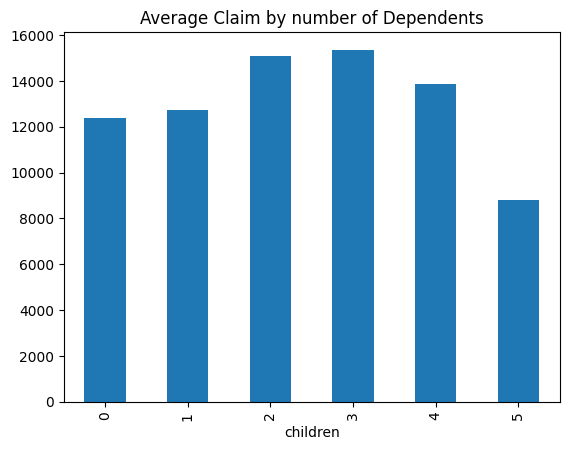

In [13]:
children_claim.plot(kind="bar", title="Average Claim by number of Dependents")
plt.show()

5. Does BMI influence insurance claims?

In [14]:
df["bmi"].corr(df["charges in INR"])

np.float64(0.19834096883362895)

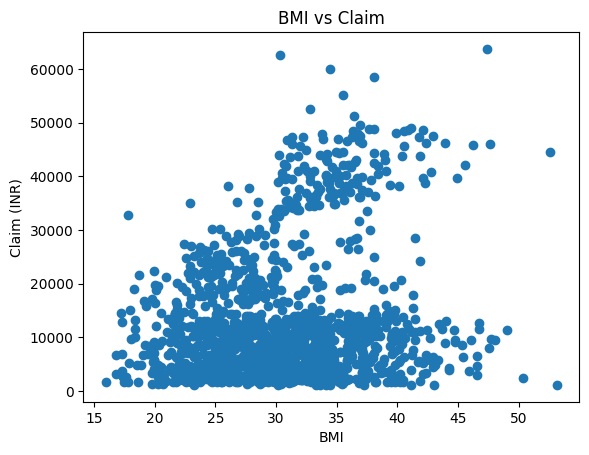

In [15]:
plt.scatter(df["bmi"], df["charges in INR"])
plt.title("BMI vs Claim")
plt.xlabel("BMI")
plt.ylabel("Claim (INR)")
plt.show()

6. Is smoking status important?

In [16]:
smoker_claim = df.groupby("smoker")["charges in INR"].mean()
smoker_claim

,charges in INR
smoker,
no,8434.268298
yes,32050.231832


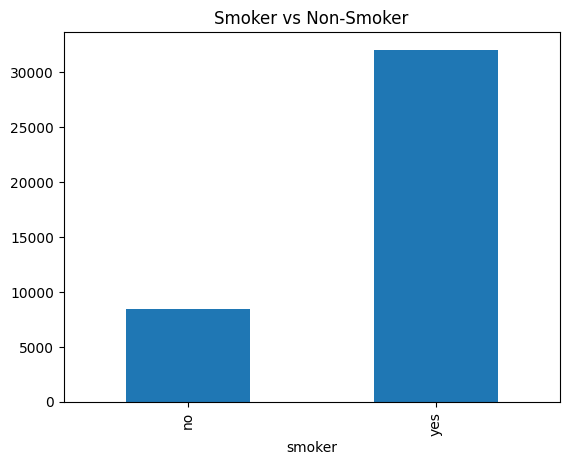

In [17]:
smoker_claim.plot(kind="bar", title="Smoker vs Non-Smoker")
plt.show()

7. Does age affect insurance claims?

In [18]:
df["age"].corr(df["charges in INR"])


np.float64(0.29900819333064754)

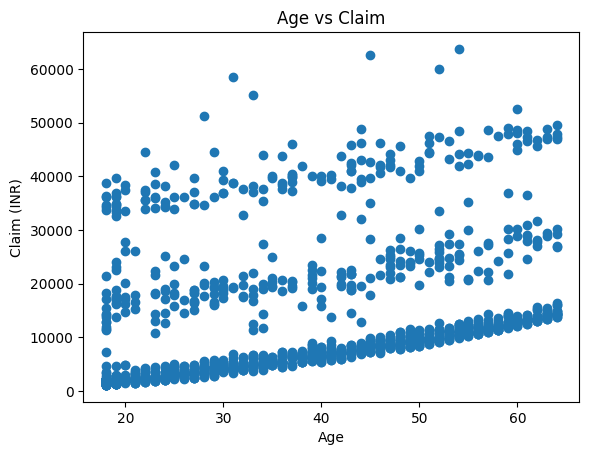

In [19]:
plt.scatter(df["age"], df["charges in INR"])
plt.title("Age vs Claim")
plt.xlabel("Age")
plt.ylabel("Claim (INR)")
plt.show()

8. Can Medibuddy offer discounts based on BMI(health status)

In [20]:
healthy = df[df["bmi"] < 25]["charges in INR"].mean()
unhealthy = df[df["bmi"] >= 25]["charges in INR"].mean()

healthy, unhealthy

(np.float64(10282.224474367347), np.float64(13940.237872405307))